# Tugas Machine Learning – Dataset Shopping Trends

**Tujuan:** melakukan analisis dan pemodelan Machine Learning untuk memprediksi **nilai pembelian pelanggan (`Purchase Amount (USD)`)** berdasarkan karakteristik pelanggan dan transaksinya pada dataset *Customer Shopping Trends*.

Karena target berupa angka kontinu (USD), metode yang digunakan adalah **regresi**. Empat model dibandingkan: Linear Regression, Decision Tree, Random Forest, dan Gradient Boosting.

## 1. Loading

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import pickle

# Membaca dataset shopping trends
df = pd.read_csv("shopping_trends_updated.csv")

# Menampilkan 5 baris pertama
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


## 2. Cleaning & Transforming

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   str    
 3   Item Purchased          3900 non-null   str    
 4   Category                3900 non-null   str    
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   str    
 7   Size                    3900 non-null   str    
 8   Color                   3900 non-null   str    
 9   Season                  3900 non-null   str    
 10  Review Rating           3900 non-null   float64
 11  Subscription Status     3900 non-null   str    
 12  Shipping Type           3900 non-null   str    
 13  Discount Applied        3900 non-null   str    
 14  Promo Code Used         3900 non-null   str    
 15

In [3]:
# Statistik deskriptif (include='all' supaya kolom teks ikut tampil)
df.describe(include="all")

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3900.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.749949,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716223,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.700000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


In [4]:
# Cek missing value
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

**Catatan Data:**
- Dataset terdiri dari 3.900 baris dan 18 kolom yang berisi informasi pelanggan dan transaksi belanja.
- Berdasarkan pemeriksaan awal, tidak ditemukan missing value pada seluruh kolom.
- Kolom numerik: `Customer ID`, `Age`, `Purchase Amount (USD)`, `Review Rating`, `Previous Purchases`.
- Kolom kategorikal: `Gender`, `Item Purchased`, `Category`, `Location`, `Size`, `Color`, `Season`, `Subscription Status`, `Shipping Type`, `Discount Applied`, `Promo Code Used`, `Payment Method`, `Frequency of Purchases`.
- `Customer ID` hanya pengenal unik pelanggan, sehingga **tidak dipakai sebagai fitur**.

In [5]:
# =========================
# DATA CLEANING DATASET SHOPPING TRENDS
# =========================

print("Missing Value Sebelum Cleaning:")
display(df.isnull().sum())

# Kolom numerik diisi median
kolom_numerik = df.select_dtypes(include='number').columns
for col in kolom_numerik:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Kolom kategorikal diisi 'Unknown'
kolom_kategorikal = df.select_dtypes(exclude='number').columns
for col in kolom_kategorikal:
    if df[col].isnull().any():
        df[col] = df[col].fillna('Unknown')

print("\nMissing Value Setelah Cleaning:")
display(df.isnull().sum())

print("\nUkuran Dataset:", df.shape)
print("\nStatistik Deskriptif:")
display(df.describe())
print("\nContoh Data:")
display(df.head())

Missing Value Sebelum Cleaning:


Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64


Missing Value Setelah Cleaning:


Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64


Ukuran Dataset: (3900, 18)

Statistik Deskriptif:


,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000



Contoh Data:


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [6]:
# Cek & hapus duplikat
print("Jumlah duplikat:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape setelah drop duplikat:", df.shape)

Jumlah duplikat: 0
Shape setelah drop duplikat: (3900, 18)


### Feature Engineering

Kolom kategorikal seperti `Gender`, `Item Purchased`, `Category`, `Location`, `Size`, `Color`, `Season`, `Subscription Status`, `Shipping Type`, `Discount Applied`, `Promo Code Used`, `Payment Method`, dan `Frequency of Purchases` perlu diubah menjadi fitur numerik menggunakan encoding. Kolom numerik `Age`, `Review Rating`, dan `Previous Purchases` dipakai langsung sebagai fitur.

**Kolom `Purchase Amount (USD)` digunakan sebagai target**, sehingga tidak dimasukkan sebagai fitur input untuk menghindari *data leakage*. Kolom `Customer ID` dibuang karena hanya identifier dan tidak membawa informasi prediktif.

In [7]:
fe = df.copy()

# Buang identifier (bukan fitur prediktif)
fe = fe.drop(columns=['Customer ID'])

print("Ukuran dataset:", fe.shape)
print("\nKolom dataset:")
print(fe.columns.tolist())
print("\nContoh hasil feature engineering:")
display(fe.head())

Ukuran dataset: (3900, 17)

Kolom dataset:
['Age', 'Gender', 'Item Purchased', 'Category', 'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season', 'Review Rating', 'Subscription Status', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Previous Purchases', 'Payment Method', 'Frequency of Purchases']

Contoh hasil feature engineering:


,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


### Outlier

Nilai pada kolom numerik (`Age`, `Purchase Amount (USD)`, `Review Rating`, `Previous Purchases`) diperiksa dengan boxplot dan metode IQR. Nilai ekstrem belum tentu salah catat, sehingga data **tidak dihapus** hanya berdasarkan IQR; penghapusan hanya dilakukan jika ditemukan nilai tidak valid.

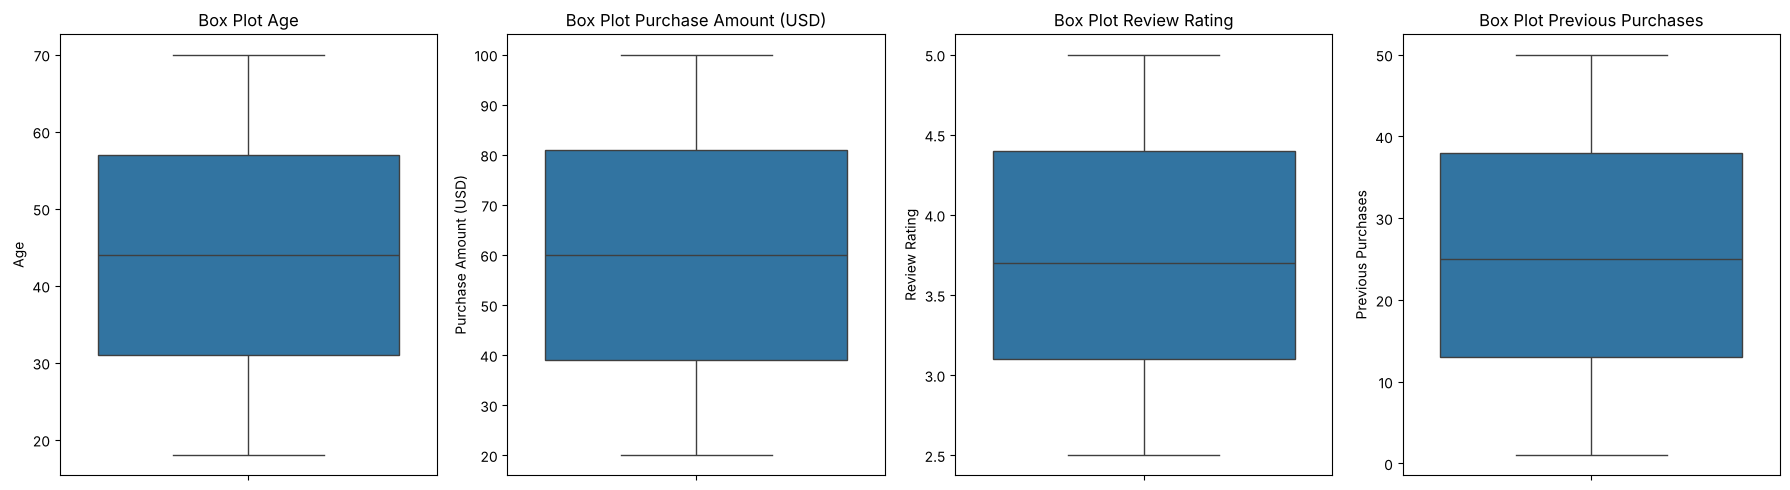

In [8]:
num_cols = ['Age', 'Purchase Amount (USD)', 'Review Rating', 'Previous Purchases']

fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f'Box Plot {col}')
plt.tight_layout()
plt.show()

In [9]:
# Hitung jumlah outlier (IQR) hanya sebagai informasi
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    jumlah = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'{col}: {jumlah} data terdeteksi sebagai outlier')

# Data asli tidak dihapus atau diubah

Age: 0 data terdeteksi sebagai outlier
Purchase Amount (USD): 0 data terdeteksi sebagai outlier
Review Rating: 0 data terdeteksi sebagai outlier
Previous Purchases: 0 data terdeteksi sebagai outlier


### Encoding

Kolom kategorikal diubah menjadi representasi numerik dengan **One-Hot Encoding** (`drop_first=True` untuk menghindari multikolinearitas). Kolom numerik dipertahankan. Kolom target `Purchase Amount (USD)` dipisahkan sebagai `y` dan tidak ikut di-encode.

In [10]:
# Target: nilai pembelian
y = fe['Purchase Amount (USD)']

# Fitur: semua kolom kecuali target
X = fe.drop(columns=['Purchase Amount (USD)'])

# One-Hot Encoding untuk semua fitur kategorikal
kolom_kategorikal = X.select_dtypes(exclude='number').columns.tolist()
X = pd.get_dummies(X, columns=kolom_kategorikal, drop_first=True, dtype=int)

# Pastikan semua fitur numerik
X = X.astype(float)

print("Kolom kategorikal di-encode:", kolom_kategorikal)
print("Ukuran fitur X:", X.shape)
print("Ukuran target y:", y.shape)
display(X.head())
display(y.head())

Kolom kategorikal di-encode: ['Gender', 'Item Purchased', 'Category', 'Location', 'Size', 'Color', 'Season', 'Subscription Status', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Payment Method', 'Frequency of Purchases']
Ukuran fitur X: (3900, 129)
Ukuran target y: (3900,)


,Age,Review Rating,Previous Purchases,Gender_Male,Item Purchased_Belt,Item Purchased_Blouse,Item Purchased_Boots,Item Purchased_Coat,Item Purchased_Dress,Item Purchased_Gloves,...,Payment Method_Credit Card,Payment Method_Debit Card,Payment Method_PayPal,Payment Method_Venmo,Frequency of Purchases_Bi-Weekly,Frequency of Purchases_Every 3 Months,Frequency of Purchases_Fortnightly,Frequency of Purchases_Monthly,Frequency of Purchases_Quarterly,Frequency of Purchases_Weekly
0,55.0,3.1,14.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,19.0,3.1,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,50.0,3.1,23.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,21.0,3.5,49.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,45.0,2.7,31.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


0    53
1    64
2    73
3    90
4    49
Name: Purchase Amount (USD), dtype: int64

## 3. EDA

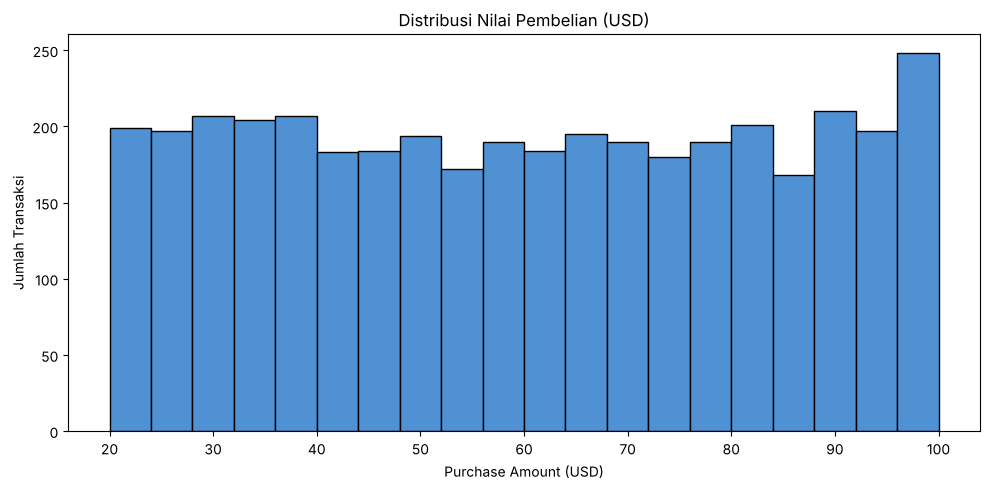

In [11]:
# Distribusi nilai pembelian
plt.figure(figsize=(10, 5))
df['Purchase Amount (USD)'].plot(kind='hist', bins=20, color='#5091d4', edgecolor='black')
plt.title('Distribusi Nilai Pembelian (USD)')
plt.xlabel('Purchase Amount (USD)')
plt.ylabel('Jumlah Transaksi')
plt.tight_layout()
plt.show()

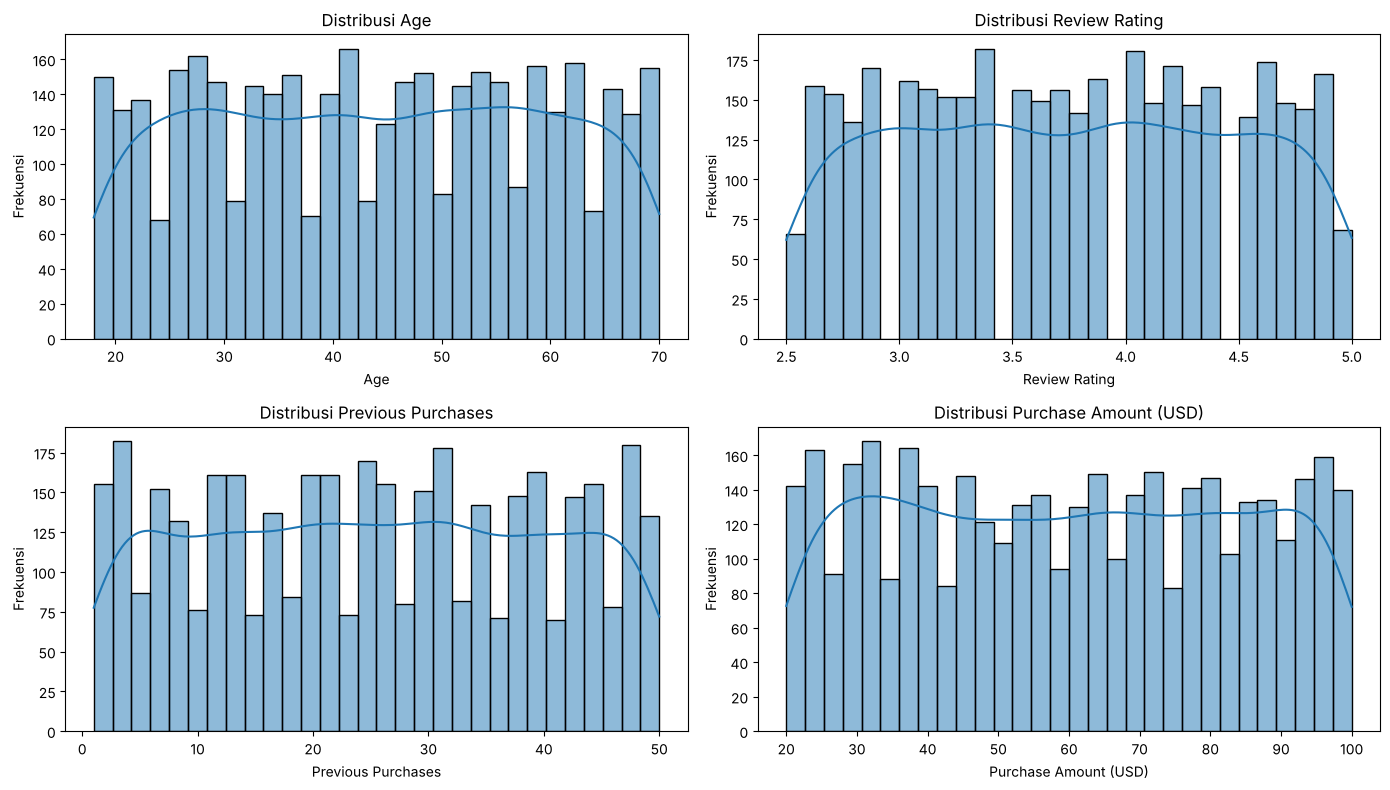

In [12]:
# Distribusi fitur numerik
cols = ['Age', 'Review Rating', 'Previous Purchases', 'Purchase Amount (USD)']

plt.figure(figsize=(14, 8))
for i, col in enumerate(cols, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

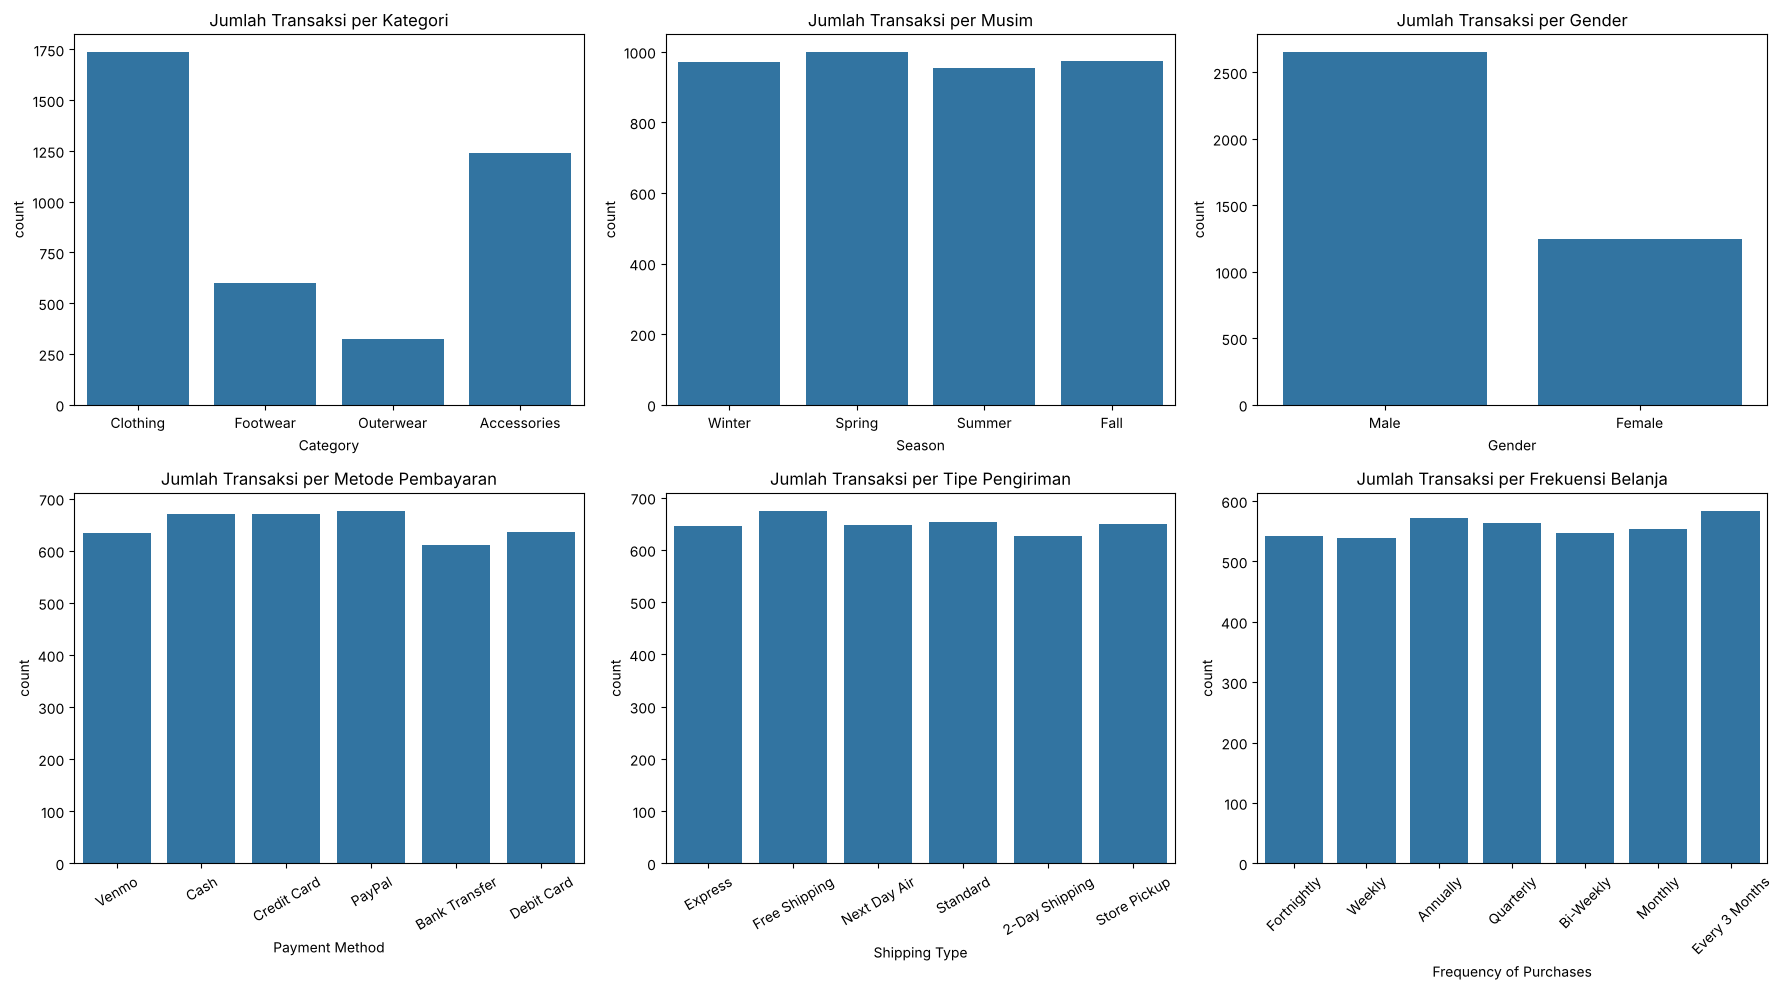

In [13]:
# Distribusi fitur kategorikal
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.countplot(data=df, x='Category', ax=axes[0, 0])
axes[0, 0].set_title('Jumlah Transaksi per Kategori')

sns.countplot(data=df, x='Season', ax=axes[0, 1])
axes[0, 1].set_title('Jumlah Transaksi per Musim')

sns.countplot(data=df, x='Gender', ax=axes[0, 2])
axes[0, 2].set_title('Jumlah Transaksi per Gender')

sns.countplot(data=df, x='Payment Method', ax=axes[1, 0])
axes[1, 0].set_title('Jumlah Transaksi per Metode Pembayaran')
axes[1, 0].tick_params(axis='x', rotation=30)

sns.countplot(data=df, x='Shipping Type', ax=axes[1, 1])
axes[1, 1].set_title('Jumlah Transaksi per Tipe Pengiriman')
axes[1, 1].tick_params(axis='x', rotation=30)

sns.countplot(data=df, x='Frequency of Purchases', ax=axes[1, 2])
axes[1, 2].set_title('Jumlah Transaksi per Frekuensi Belanja')
axes[1, 2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

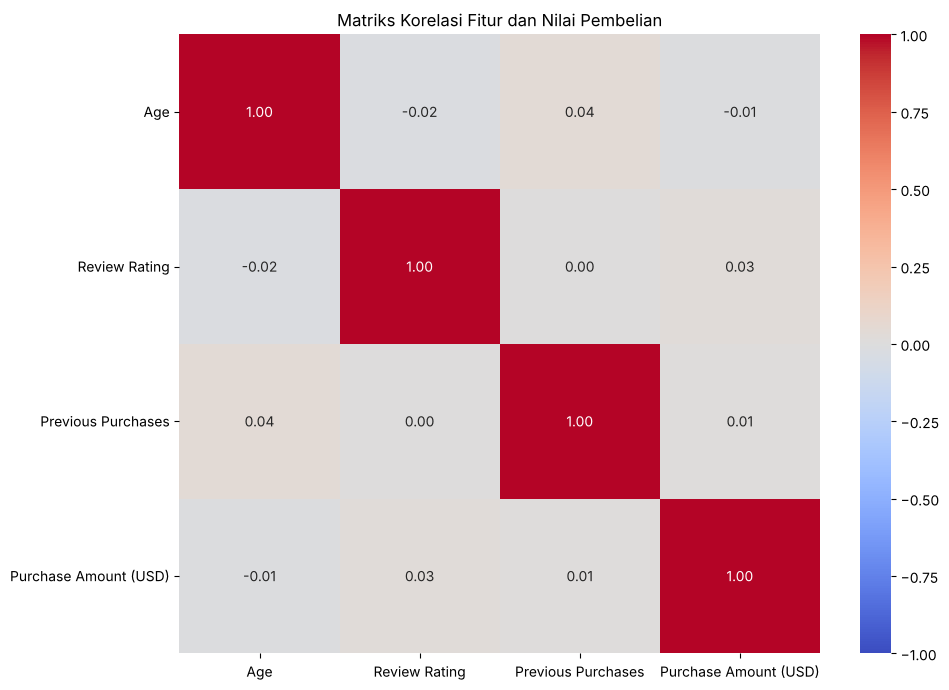

In [14]:
# Korelasi fitur numerik dan target
data_corr = df[['Age', 'Review Rating', 'Previous Purchases', 'Purchase Amount (USD)']].copy()
corr_matrix = data_corr.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriks Korelasi Fitur dan Nilai Pembelian')
plt.tight_layout()
plt.show()

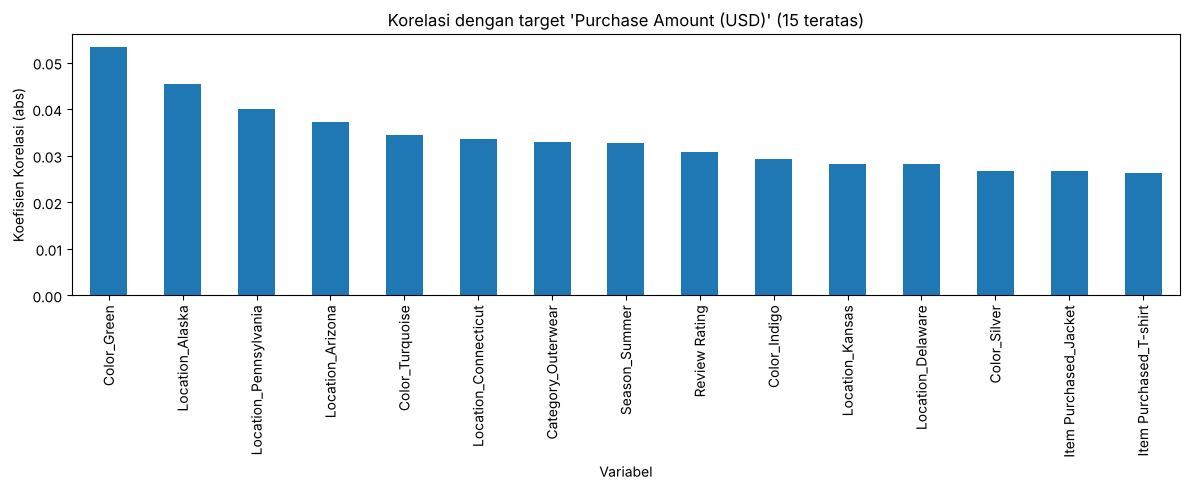

In [15]:
# Korelasi semua fitur (hasil encoding) terhadap target
target_corr = X.corrwith(y).abs().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
target_corr.head(15).plot(kind='bar')
plt.title("Korelasi dengan target 'Purchase Amount (USD)' (15 teratas)")
plt.xlabel('Variabel')
plt.ylabel('Koefisien Korelasi (abs)')
plt.tight_layout()
plt.show()

## 4. Splitting

Dataset dibagi menjadi data latih dan data uji **sebelum** scaling agar tidak terjadi *data leakage*. Proporsi **80% data latih dan 20% data uji**. Karena target berupa angka kontinu (regresi), parameter `stratify` tidak digunakan.

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])
print("Jumlah fitur:", X_train.shape[1])

Jumlah data training: 3120
Jumlah data testing: 780
Jumlah fitur: 129


In [17]:
print("Rentang nilai pembelian data latih:")
print(y_train.describe())
print("\nRentang nilai pembelian data test:")
print(y_test.describe())

Rentang nilai pembelian data latih:
count    3120.000000
mean       60.142949
std        23.677730
min        20.000000
25%        39.000000
50%        60.000000
75%        81.000000
max       100.000000
Name: Purchase Amount (USD), dtype: float64

Rentang nilai pembelian data test:
count    780.000000
mean      58.250000
std       23.670672
min       20.000000
25%       36.000000
50%       58.000000
75%       79.000000
max      100.000000
Name: Purchase Amount (USD), dtype: float64


In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit hanya pada data latih
X_train_scaled = scaler.fit_transform(X_train)

# Transform data test dengan scaler yang sama
X_test_scaled = scaler.transform(X_test)

print("Standardisasi data berhasil!")
print("Ukuran data latih:", X_train_scaled.shape)
print("Ukuran data test :", X_test_scaled.shape)

Standardisasi data berhasil!
Ukuran data latih: (3120, 129)
Ukuran data test : (780, 129)


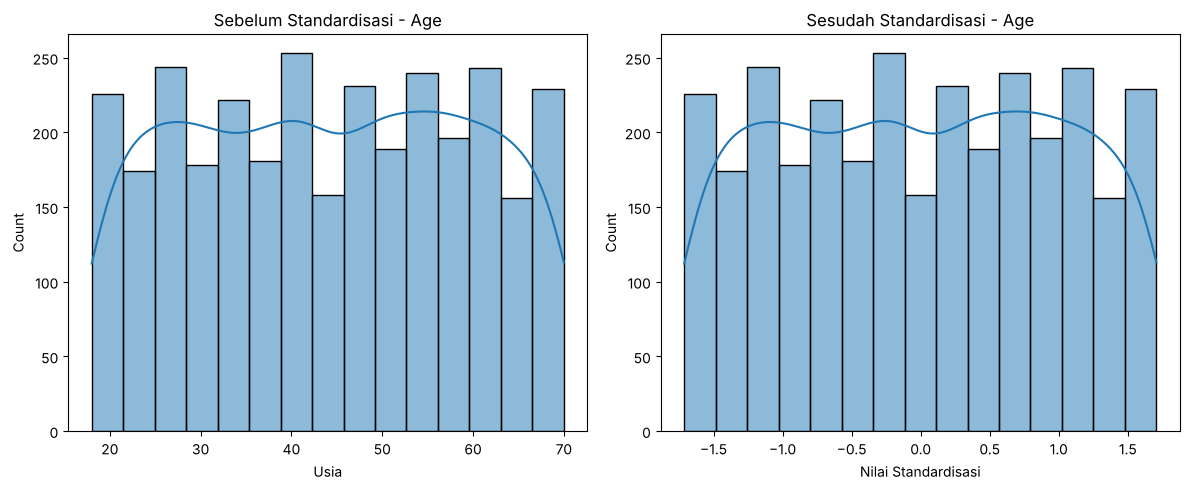

In [19]:
# Histogram sebelum vs sesudah standardisasi (fitur Age)
fitur = 'Age'
idx = list(X_train.columns).index(fitur)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(X_train[fitur], kde=True)
plt.title('Sebelum Standardisasi - Age')
plt.xlabel('Usia')

plt.subplot(1, 2, 2)
sns.histplot(X_train_scaled[:, idx], kde=True)
plt.title('Sesudah Standardisasi - Age')
plt.xlabel('Nilai Standardisasi')

plt.tight_layout()
plt.show()

## 5. Modeling

Target `Purchase Amount (USD)` berupa angka kontinu, sehingga digunakan algoritma regresi:

| Model | Keterangan |
|---|---|
| Linear Regression | Baseline sederhana (memakai data terstandardisasi) |
| Decision Tree Regressor | Aturan berbentuk pohon |
| Random Forest Regressor | Gabungan banyak pohon keputusan |
| Gradient Boosting Regressor | Pohon dibangun bertahap memperbaiki error sebelumnya |

Semua model dievaluasi pada data uji yang sama dengan metrik MAE, MSE, RMSE, dan R².

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Model 1: Linear Regression
LR = LinearRegression()
LR.fit(X_train_scaled, y_train)

# Model 2: Decision Tree Regressor
DT = DecisionTreeRegressor(max_depth=6, random_state=42)
DT.fit(X_train, y_train)

# Model 3: Random Forest Regressor
RF = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
RF.fit(X_train, y_train)

# Model 4: Gradient Boosting Regressor
GBR = GradientBoostingRegressor(random_state=42)
GBR.fit(X_train, y_train)

print("Semua model regresi berhasil dilatih!")

Semua model regresi berhasil dilatih!


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluasi(nama, model, X_test_data, y_test_data):
    pred = model.predict(X_test_data)
    mae = mean_absolute_error(y_test_data, pred)
    mse = mean_squared_error(y_test_data, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_data, pred)
    return {'Model': nama, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2 Score': r2}

hasil = [
    evaluasi('Linear Regression', LR, X_test_scaled, y_test),
    evaluasi('Decision Tree', DT, X_test, y_test),
    evaluasi('Random Forest', RF, X_test, y_test),
    evaluasi('Gradient Boosting', GBR, X_test, y_test)
]

df_results = pd.DataFrame(hasil).set_index('Model').round(4)
display(df_results)

,MAE,MSE,RMSE,R2 Score
Model,,,,
Linear Regression,20.9023,575.3492,23.9864,-0.0282
Decision Tree,21.2638,600.3836,24.5027,-0.0729
Random Forest,21.0021,577.9756,24.0411,-0.0329
Gradient Boosting,20.7932,566.9065,23.8098,-0.0131


In [22]:
# Pembanding: baseline yang selalu menebak rata-rata data latih
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy='mean').fit(X_train, y_train)
display(pd.DataFrame([evaluasi('Baseline (rata-rata)', dummy, X_test, y_test)]).set_index('Model').round(4))

,MAE,MSE,RMSE,R2 Score
Model,,,,
Baseline (rata-rata),20.7559,563.1656,23.7311,-0.0064


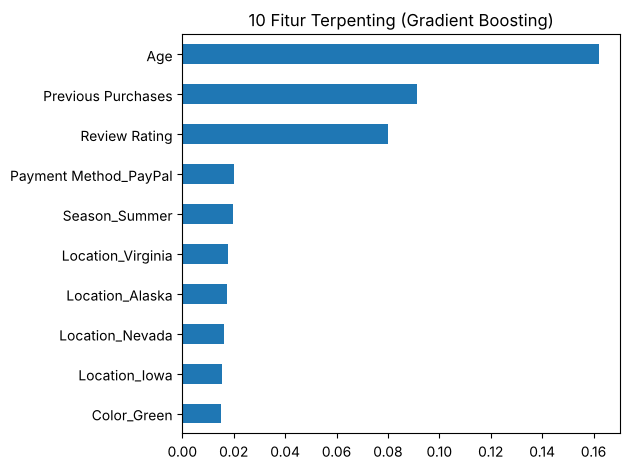

In [23]:
imp = pd.Series(GBR.feature_importances_, index=X_train.columns).sort_values(ascending=False)
imp.head(10).plot(kind='barh').invert_yaxis()
plt.title('10 Fitur Terpenting (Gradient Boosting)')
plt.tight_layout()
plt.show()

## 6. Menyimpan Model Terbaik

Model terbaik dipilih berdasarkan **RMSE terendah** pada data uji, lalu disimpan dengan `joblib` dan `pickle`.

In [24]:
models = {'Linear Regression': LR, 'Decision Tree': DT, 'Random Forest': RF, 'Gradient Boosting': GBR}

nama_terbaik = df_results['RMSE'].idxmin()
best_model = models[nama_terbaik]
print("Model terbaik (RMSE terendah):", nama_terbaik)

joblib.dump(best_model, 'best_model.joblib')

with open('best_model.pkl', 'wb') as file:
    pickle.dump(best_model, file)

# Scaler ikut disimpan karena Linear Regression butuh data terstandardisasi
joblib.dump(scaler, 'scaler.joblib')

Model terbaik (RMSE terendah): Gradient Boosting


['scaler.joblib']